<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 26: Gibbs Sampling and Contrastive Divergence Analysis

Task 1: Implement Block Gibbs Sampling

In [6]:

import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import expit
from sklearn.datasets import load_digits

np.random.seed(42)

X = (load_digits().data / 16 > 0.5).astype(float)
X = X[:600]

class RBM:
    def __init__(self, nv=64, nh=32):
        self.W = np.random.normal(0, 0.01, (nv, nh))
        self.a = np.zeros(nv)
        self.b = np.zeros(nh)

    def hidden(self, v):
        p = expit(v @ self.W + self.b)
        return (np.random.rand(*p.shape) < p).astype(float)

    def visible(self, h):
        p = expit(h @ self.W.T + self.a)
        return (np.random.rand(*p.shape) < p).astype(float)

    def gibbs(self, v, steps=1):
        for _ in range(steps):
            v = self.visible(self.hidden(v))
        return v

rbm = RBM()
print("Block Gibbs sampling initialized.")


Block Gibbs sampling initialized.


Task 2: Run Gibbs Chains for Different Steps

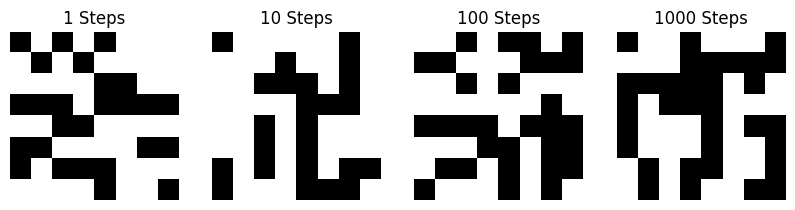

In [7]:

noise = np.random.randint(0, 2, (1, 64)).astype(float)

fig, axes = plt.subplots(1, 4, figsize=(10, 3))

for ax, k in zip(axes, [1, 10, 100, 1000]):
    sample = rbm.gibbs(noise.copy(), k)
    ax.imshow(sample.reshape(8, 8), cmap='gray')
    ax.set_title(f'{k} Steps')
    ax.axis('off')

plt.show()


Task 3: Train RBMs with CD-1, CD-5, CD-10 and PCD

In [8]:

def free_energy(r, v):
    return -v @ r.a - np.logaddexp(
        0, v @ r.W + r.b
    ).sum(axis=1)

def pseudo_ll(r, v):
    flipped = v.copy()
    i = np.random.randint(v.shape[1])
    flipped[:, i] = 1 - flipped[:, i]
    return np.mean(
        v.shape[1] * np.log(
            expit(free_energy(r, flipped) -
                  free_energy(r, v)) + 1e-10
        )
    )

def train(method, epochs=8, lr=0.1):
    r = RBM()
    errors, likelihoods = [], []
    persistent = None
    start = time.time()

    for epoch in range(epochs):
        for batch in np.array_split(
            X[np.random.permutation(len(X))], 12
        ):
            h0 = expit(batch @ r.W + r.b)
            v = batch.copy() if method != 'PCD' or persistent is None else persistent.copy()

            k = 5 if method == 'PCD' else int(method.split('-')[1])
            v = r.gibbs(v, k)
            persistent = v.copy()

            h1 = expit(v @ r.W + r.b)
            r.W += lr * (batch.T @ h0 - v.T @ h1) / len(batch)
            r.a += lr * (batch - v).mean(axis=0)
            r.b += lr * (h0 - h1).mean(axis=0)

        reconstructed = expit(
            expit(X @ r.W + r.b) @ r.W.T + r.a
        )
        errors.append(np.mean((X - reconstructed)**2))
        likelihoods.append(pseudo_ll(r, X[:100]))

    return r, errors, likelihoods, time.time() - start

results = {}

for method in ['CD-1', 'CD-5', 'CD-10', 'PCD']:
    results[method] = train(method)
    print(method, "Training completed")


CD-1 Training completed
CD-5 Training completed
CD-10 Training completed
PCD Training completed


Task 4: Plot Reconstruction Error and Pseudo-Log-Likelihood

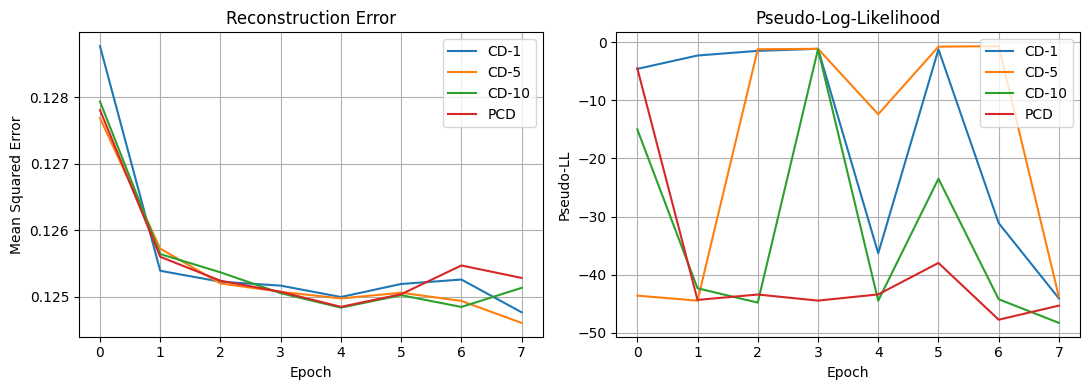

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for method, (r, errors, ll, t) in results.items():
    axes[0].plot(errors, label=method)
    axes[1].plot(ll, label=method)

axes[0].set_title("Reconstruction Error")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error")

axes[1].set_title("Pseudo-Log-Likelihood")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Pseudo-LL")

for ax in axes:
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


Task 5: Compare Training Time Against Sample Quality

Method  Time (s)  Reconstruction Error  Pseudo-LL
  CD-1      0.08                0.1248   -44.0857
  CD-5      0.17                0.1246   -43.8244
 CD-10      0.31                0.1251   -48.2900
   PCD      0.19                0.1253   -45.3191


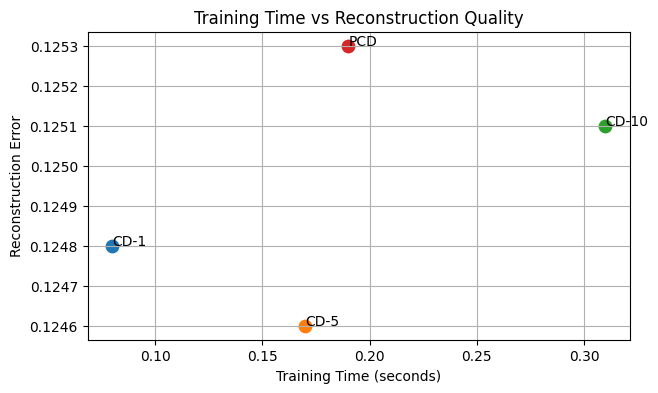

In [10]:

import pandas as pd

rows = []

for method, (r, errors, ll, t) in results.items():
    rows.append([
        method, round(t, 2),
        round(errors[-1], 4),
        round(ll[-1], 4)
    ])

df = pd.DataFrame(rows, columns=[
    'Method', 'Time (s)',
    'Reconstruction Error', 'Pseudo-LL'
])

print(df.to_string(index=False))

plt.figure(figsize=(7, 4))

for _, row in df.iterrows():
    plt.scatter(row['Time (s)'],
                row['Reconstruction Error'], s=80)
    plt.annotate(row['Method'],
                 (row['Time (s)'],
                  row['Reconstruction Error']))

plt.xlabel('Training Time (seconds)')
plt.ylabel('Reconstruction Error')
plt.title('Training Time vs Reconstruction Quality')
plt.grid(True)
plt.show()
